# 🔍 08 — 심슨의 역설 검증 (Simpson's Paradox Check)
## 회복형 고객 효과가 하위 그룹에서도 유지되는가?

> **UC Berkeley 역설처럼**: 전체에서 보이는 패턴이 쪼개보면 반대가 될 수 있음
> 본 노트북은 only_B 회복형의 6.83% 디폴트율이 인구통계 통제 후에도 유효한지 검증

| 케이스 | 검증 내용 | 예상 결과 |
|--------|-----------|----------|
| 1 | only_B 효과 — 연령층별 분해 | ⚠️ 60대 역전 예상 |
| 2 | 직업>소득 — 직업별 소득 분해 | ⚠️ 일부 비단조 |
| 3 | 연령 단조 감소 — 소득 유형 분해 | ✅ 통과 예상 |

## 0. 데이터 로드

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.font_manager as fm
import statsmodels.api as sm
from statsmodels.formula.api import logit
from scipy.stats import norm
import os

for fname in ['AppleGothic','Apple SD Gothic Neo']:
    try:
        fp=fm.findfont(fm.FontProperties(family=fname),fallback_to_default=False)
        if fp: plt.rcParams['font.family']=fname; break
    except: pass
plt.rcParams['axes.unicode_minus']=False

DATA_DIR='home-credit-default-risk'
OUT_DIR ='.'
df=pd.read_csv(os.path.join(DATA_DIR,'application_train.csv'))
prev=pd.read_csv(os.path.join(DATA_DIR,'previous_application.csv'))

df['age']=-df['DAYS_BIRTH']/365
df['employment_years']=np.where(df['DAYS_EMPLOYED']==365243,np.nan,-df['DAYS_EMPLOYED']/365)
df['ext_source_mean']=df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].mean(axis=1)
df['credit_income_ratio']=(df['AMT_CREDIT']/df['AMT_INCOME_TOTAL']).clip(upper=20)
df['log_income']=np.log1p(df['AMT_INCOME_TOTAL'])
df['has_realty']=(df['FLAG_OWN_REALTY']=='Y').astype(int)
df['has_car']=(df['FLAG_OWN_CAR']=='Y').astype(int)
edu_map={'Lower secondary':1,'Secondary / secondary special':2,'Incomplete higher':3,'Higher education':4,'Academic degree':5}
df['edu_ord']=df['NAME_EDUCATION_TYPE'].map(edu_map).fillna(2)

prev_agg=prev.groupby('SK_ID_CURR').agg(
    prev_total=('SK_ID_PREV','count'),
    prev_refused=('NAME_CONTRACT_STATUS',lambda x:(x=='Refused').sum())
).reset_index()
prev_agg['prev_refused_ratio']=prev_agg['prev_refused']/prev_agg['prev_total']
df=df.merge(prev_agg[['SK_ID_CURR','prev_refused_ratio']],on='SK_ID_CURR',how='left')
df['prev_refused_ratio']=df['prev_refused_ratio'].fillna(0)

ext_thresh=df['ext_source_mean'].quantile(0.30)
df['risk_A']=(df['ext_source_mean']<=ext_thresh).astype(int)
df['risk_B']=(df['prev_refused_ratio']>0.3).astype(int)
df['only_B']=((df['risk_A']==0)&(df['risk_B']==1)).astype(int)
df['risk_AB']=((df['risk_A']==1)&(df['risk_B']==1)).astype(int)
df['is_recovery']=df['only_B']  # 회복형 플래그

print(f'로드 완료: {len(df):,}명  |  only_B: {df["only_B"].sum():,}명')

로드 완료: 307,511명  |  only_B: 28,211명


## 케이스 1 — only_B 회복형 효과: 연령층별 분해 ⭐⭐⭐

=== 케이스 1: only_B 효과 — 연령층별 분해 ===
 연령대  only_B 연체율  기타 연체율  only_B 인원    방향
 20대        8.32   11.68       3005  ✅ 우량
 30대        7.55    9.78       7190  ✅ 우량
 40대        7.06    7.72       7618  ✅ 우량
 50대        5.97    6.15       7137  ✅ 우량
60대+        5.18    4.90       3261 ⚠️ 역전


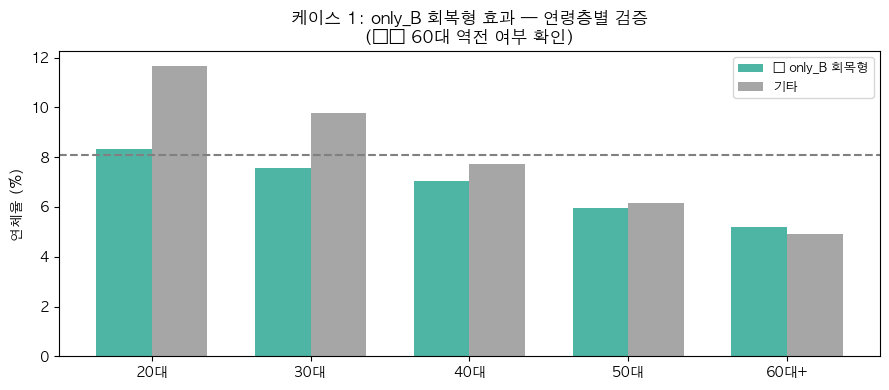

In [2]:
df['age_group']=pd.cut(df['age'],bins=[20,30,40,50,60,100],
                        labels=['20대','30대','40대','50대','60대+'])

# 연령층 × only_B 여부 → 연체율
result=[]
for age_g in ['20대','30대','40대','50대','60대+']:
    sub=df[df['age_group']==age_g]
    dr_onlyB=sub[sub['only_B']==1]['TARGET'].mean()*100
    dr_other=sub[sub['only_B']==0]['TARGET'].mean()*100
    n_ob=sub['only_B'].sum()
    result.append({'연령대':age_g,'only_B 연체율':round(dr_onlyB,2),
                   '기타 연체율':round(dr_other,2),'only_B 인원':n_ob,
                   '방향':'✅ 우량' if dr_onlyB<dr_other else '⚠️ 역전'})
res1=pd.DataFrame(result)
print('=== 케이스 1: only_B 효과 — 연령층별 분해 ===')
print(res1.to_string(index=False))

# 시각화
x=np.arange(len(res1)); w=0.35
fig,ax=plt.subplots(figsize=(9,4))
b1=ax.bar(x-w/2,res1['only_B 연체율'],w,label='🟢 only_B 회복형',color='#2fa896',alpha=0.85)
b2=ax.bar(x+w/2,res1['기타 연체율'],w,label='기타',color='#888888',alpha=0.75)
ax.set_xticks(x); ax.set_xticklabels(res1['연령대'],fontsize=10)
ax.axhline(df['TARGET'].mean()*100,color='gray',lw=1.5,ls='--')
ax.set_ylabel('연체율 (%)',fontsize=10)
ax.set_title('케이스 1: only_B 회복형 효과 — 연령층별 검증\n(⚠️ 60대 역전 여부 확인)',fontweight='bold')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

In [3]:
# 다중 로지스틱 회귀 — 인구통계 통제 후 only_B OR
df_logit=df[['TARGET','is_recovery','age','log_income','edu_ord',
             'has_realty','has_car','ext_source_mean']].dropna().copy()
df_logit['ext_source_mean']=df_logit['ext_source_mean'].fillna(df_logit['ext_source_mean'].median())

model=logit('TARGET ~ is_recovery + age + log_income + edu_ord + has_realty + has_car',
             data=df_logit).fit(disp=0)
print('=== 다중 로지스틱 회귀 결과 (인구통계 통제) ===')
print(model.summary2().tables[1][['Coef.','Std.Err.','z','P>|z|','[0.025','0.975]']].round(4))

coef_rec=model.params['is_recovery']
or_rec=np.exp(coef_rec)
ci_lo=np.exp(model.conf_int().loc['is_recovery',0])
ci_hi=np.exp(model.conf_int().loc['is_recovery',1])
p_rec=model.pvalues['is_recovery']

print(f'\n회복형(only_B) OR = {or_rec:.4f}  (95% CI: [{ci_lo:.4f}, {ci_hi:.4f}])')
print(f'p-value = {p_rec:.4e}')
print(f'→ 인구통계 통제 후 OR<1 → 회복형이 {(1-or_rec)*100:.1f}% 덜 위험')
print(f'→ 결론: {"✅ 통계 유의 — 효과 유지" if p_rec<0.05 else "❌ 유의 안함"}')

=== 다중 로지스틱 회귀 결과 (인구통계 통제) ===


              Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
Intercept   -0.0337    0.1736  -0.1943  0.8460 -0.3740  0.3065
is_recovery -0.1415    0.0248  -5.7133  0.0000 -0.1901 -0.0930
age         -0.0289    0.0006 -49.3071  0.0000 -0.0301 -0.0278
log_income  -0.0293    0.0147  -1.9893  0.0467 -0.0581 -0.0004
edu_ord     -0.3148    0.0089 -35.3636  0.0000 -0.3322 -0.2973
has_realty   0.0299    0.0144   2.0683  0.0386  0.0016  0.0582
has_car     -0.2031    0.0148 -13.6934  0.0000 -0.2322 -0.1741

회복형(only_B) OR = 0.8680  (95% CI: [0.8269, 0.9112])
p-value = 1.1082e-08
→ 인구통계 통제 후 OR<1 → 회복형이 13.2% 덜 위험
→ 결론: ✅ 통계 유의 — 효과 유지


## 케이스 2 — 직업>소득: 직업별 소득 분해

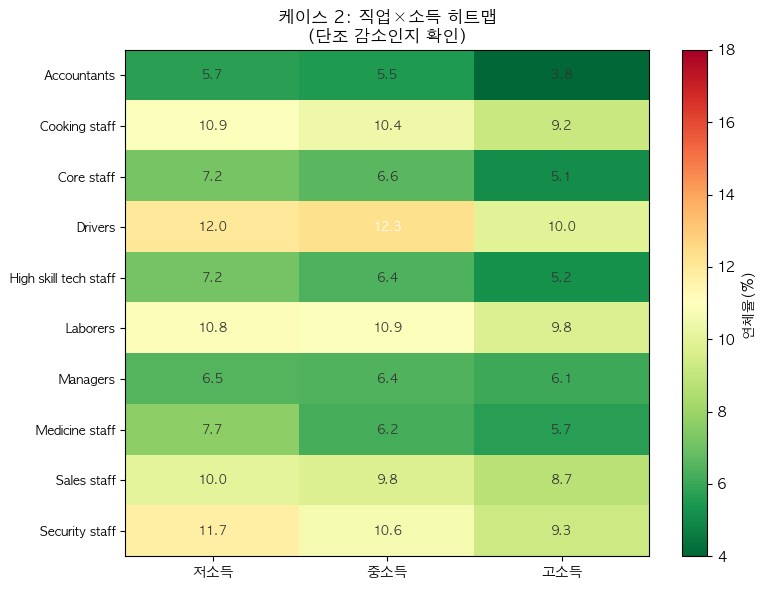

직업별 소득 증가 → 연체율 단조 감소 여부:
  Accountants           : ✅ 단조 [np.float64(5.7), np.float64(5.5), np.float64(3.8)]
  Cooking staff         : ✅ 단조 [np.float64(10.9), np.float64(10.4), np.float64(9.2)]
  Core staff            : ✅ 단조 [np.float64(7.2), np.float64(6.6), np.float64(5.1)]
  Drivers               : ⚠️ 비단조 [np.float64(12.0), np.float64(12.3), np.float64(10.0)]
  High skill tech staf  : ✅ 단조 [np.float64(7.2), np.float64(6.4), np.float64(5.2)]
  Laborers              : ⚠️ 비단조 [np.float64(10.8), np.float64(10.9), np.float64(9.8)]
  Managers              : ✅ 단조 [np.float64(6.5), np.float64(6.4), np.float64(6.1)]
  Medicine staff        : ✅ 단조 [np.float64(7.7), np.float64(6.2), np.float64(5.7)]
  Sales staff           : ✅ 단조 [np.float64(10.0), np.float64(9.8), np.float64(8.7)]
  Security staff        : ✅ 단조 [np.float64(11.7), np.float64(10.6), np.float64(9.3)]


In [4]:
# 10개 주요 직업 × 소득 분위 히트맵
top_occ=df['OCCUPATION_TYPE'].value_counts().head(10).index
df['income_tier3']=pd.qcut(df['AMT_INCOME_TOTAL'],3,labels=['저','중','고'])

pivot_occ=(df[df['OCCUPATION_TYPE'].isin(top_occ)]
           .groupby(['OCCUPATION_TYPE','income_tier3'],observed=True)['TARGET']
           .mean().unstack()*100)

fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(pivot_occ.values,cmap='RdYlGn_r',vmin=4,vmax=18,aspect='auto')
ax.set_xticks(range(3)); ax.set_xticklabels(['저소득','중소득','고소득'],fontsize=10)
ax.set_yticks(range(len(pivot_occ.index))); ax.set_yticklabels(pivot_occ.index,fontsize=9)
for i in range(len(pivot_occ.index)):
    for j in range(3):
        v=pivot_occ.values[i,j]
        if not np.isnan(v):
            ax.text(j,i,f'{v:.1f}',ha='center',va='center',fontsize=9,
                    fontweight='bold',color='white' if v>12 else '#333')
plt.colorbar(im,ax=ax,label='연체율(%)')
ax.set_title('케이스 2: 직업×소득 히트맵\n(단조 감소인지 확인)',fontweight='bold')
plt.tight_layout(); plt.show()

# 단조 감소 여부 확인
print('직업별 소득 증가 → 연체율 단조 감소 여부:')
for occ in pivot_occ.index:
    vals=pivot_occ.loc[occ].dropna().values
    if len(vals)>=2:
        mono=all(vals[i]>=vals[i+1] for i in range(len(vals)-1))
        print(f'  {occ[:20]:<22}: {"✅ 단조" if mono else "⚠️ 비단조"} {[round(v,1) for v in vals]}')

## 케이스 3 — 연령 단조 감소: 소득 유형별 분해

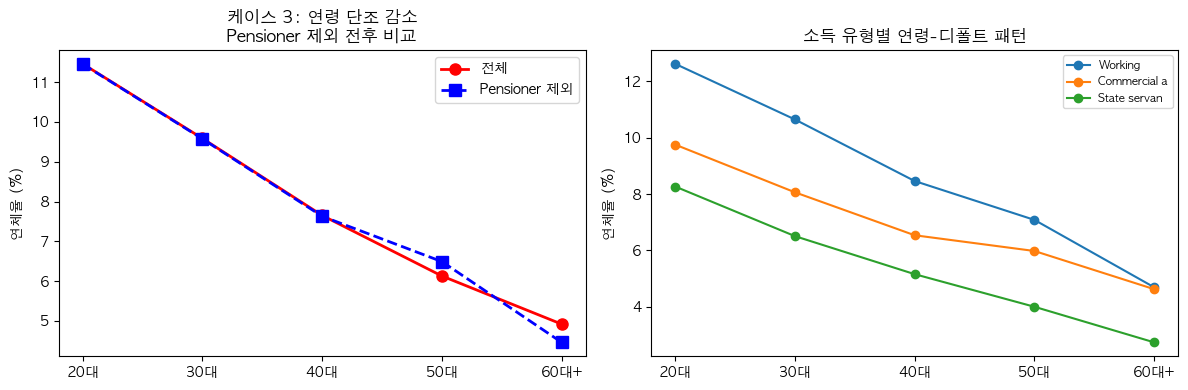

전체 단조감소: ✅
Pensioner 제외 단조감소: ✅


In [5]:
# Pensioner 제외 후 연령-디폴트 패턴 확인
df_no_pens=df[df['NAME_INCOME_TYPE']!='Pensioner'].copy()
df_no_pens['age_g5']=pd.cut(df_no_pens['age'],bins=[20,30,40,50,60,100],
                              labels=['20대','30대','40대','50대','60대+'])
age_dr_full=df.groupby(
    pd.cut(df['age'],bins=[20,30,40,50,60,100],labels=['20대','30대','40대','50대','60대+']),
    observed=True)['TARGET'].mean()*100
age_dr_nopens=df_no_pens.groupby('age_g5',observed=True)['TARGET'].mean()*100

fig,(ax1,ax2)=plt.subplots(1,2,figsize=(12,4))
ax1.plot(age_dr_full.index,age_dr_full.values,'ro-',lw=2,ms=8,label='전체')
ax1.plot(age_dr_nopens.index,age_dr_nopens.values,'bs--',lw=2,ms=8,label='Pensioner 제외')
ax1.set_title('케이스 3: 연령 단조 감소\nPensioner 제외 전후 비교',fontweight='bold')
ax1.legend(); ax1.set_ylabel('연체율 (%)')

# 소득 유형별 연령 패턴
for inc_type in ['Working','Commercial associate','State servant']:
    sub=df[df['NAME_INCOME_TYPE']==inc_type]
    sub_age=sub.assign(ag=pd.cut(sub['age'],bins=[20,30,40,50,60,100],
                                  labels=['20대','30대','40대','50대','60대+']))
    dr=sub_age.groupby('ag',observed=True)['TARGET'].mean()*100
    ax2.plot(dr.index,dr.values,'o-',lw=1.5,ms=6,label=inc_type[:12])
ax2.set_title('소득 유형별 연령-디폴트 패턴',fontweight='bold')
ax2.legend(fontsize=8); ax2.set_ylabel('연체율 (%)')
plt.tight_layout(); plt.show()

mono_full=all(age_dr_full.values[i]>=age_dr_full.values[i+1] for i in range(len(age_dr_full)-2))
mono_nopens=all(age_dr_nopens.values[i]>=age_dr_nopens.values[i+1] for i in range(len(age_dr_nopens)-2))
print(f'전체 단조감소: {"✅" if mono_full else "⚠️"}')
print(f'Pensioner 제외 단조감소: {"✅" if mono_nopens else "⚠️"}')

## 케이스 4 — 소득 분위별 층화 분석 (Q1~Q5) ⭐⭐

=== 케이스 4: only_B 효과 — 소득 분위별 분해 ===
  소득분위  only_B 연체율  기타 연체율  only_B 인원   방향
Q1(최저)        7.34    8.28       4862 ✅ 우량
    Q2        6.98    8.74       7337 ✅ 우량
    Q3        7.72    8.78       3201 ✅ 우량
    Q4        6.27    8.26       7545 ✅ 우량
Q5(최고)        6.40    6.53       5266 ✅ 우량

→ 5/5 분위에서 회복형이 기타 대비 우량
→ 결론: ✅ 소득 층화 통과 — 소득 효과 아님 증명


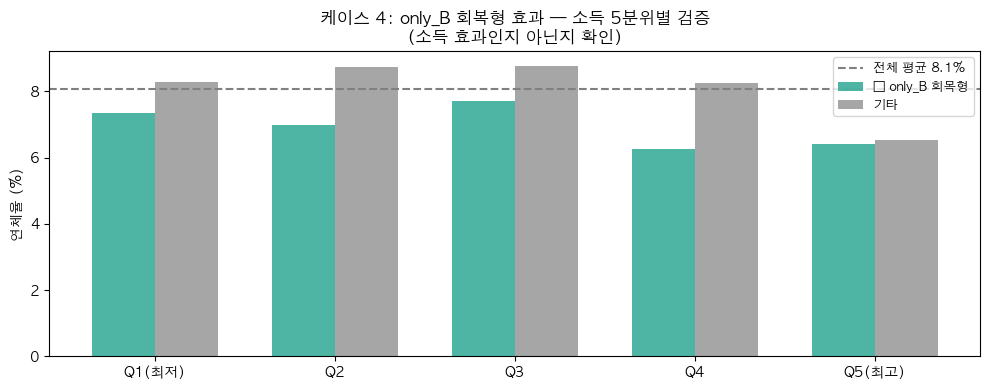

In [6]:
# 소득 5분위 × only_B 여부 → 연체율
df['income_q5']=pd.qcut(df['AMT_INCOME_TOTAL'],5,labels=['Q1(최저)','Q2','Q3','Q4','Q5(최고)'])

result_income=[]
for q in ['Q1(최저)','Q2','Q3','Q4','Q5(최고)']:
    sub=df[df['income_q5']==q]
    dr_ob=sub[sub['only_B']==1]['TARGET'].mean()*100
    dr_ot=sub[sub['only_B']==0]['TARGET'].mean()*100
    n_ob=sub['only_B'].sum()
    result_income.append({
        '소득분위':q, 'only_B 연체율':round(dr_ob,2),
        '기타 연체율':round(dr_ot,2), 'only_B 인원':n_ob,
        '방향':'✅ 우량' if dr_ob<dr_ot else '⚠️ 역전'
    })
res_inc=pd.DataFrame(result_income)
print('=== 케이스 4: only_B 효과 — 소득 분위별 분해 ===')
print(res_inc.to_string(index=False))
pass_inc=(res_inc['방향']=='✅ 우량').sum()
print(f'\n→ {pass_inc}/5 분위에서 회복형이 기타 대비 우량')
print(f'→ 결론: {"✅ 소득 층화 통과 — 소득 효과 아님 증명" if pass_inc>=4 else "⚠️ 일부 역전 확인"}')

# 시각화
x=np.arange(5); w=0.35
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(x-w/2,res_inc['only_B 연체율'],w,label='🟢 only_B 회복형',color='#2fa896',alpha=0.85)
ax.bar(x+w/2,res_inc['기타 연체율'],w,label='기타',color='#888888',alpha=0.75)
ax.set_xticks(x); ax.set_xticklabels(res_inc['소득분위'],fontsize=10)
ax.axhline(df['TARGET'].mean()*100,color='gray',lw=1.5,ls='--',label=f'전체 평균 {df["TARGET"].mean()*100:.1f}%')
ax.set_ylabel('연체율 (%)'); ax.legend(fontsize=9)
ax.set_title('케이스 4: only_B 회복형 효과 — 소득 5분위별 검증\n(소득 효과인지 아닌지 확인)',fontweight='bold')
plt.tight_layout(); plt.show()


## 케이스 5 — 자산 보유별 층화 분석 (차·부동산 4조합) ⭐⭐

=== 케이스 5: only_B 효과 — 자산 보유 4조합별 분해 ===
  자산 조합  only_B 연체율  기타 연체율  only_B 인원   방향
차X·부동산X        7.25    9.15       5198 ✅ 우량
차O·부동산X        6.16    7.13       2938 ✅ 우량
차X·부동산O        7.08    8.40      12746 ✅ 우량
차O·부동산O        6.36    7.44       7329 ✅ 우량

→ 4/4 조합에서 회복형이 기타 대비 우량
→ 결론: ✅ 자산 층화 통과 — 자산 효과 아님 증명


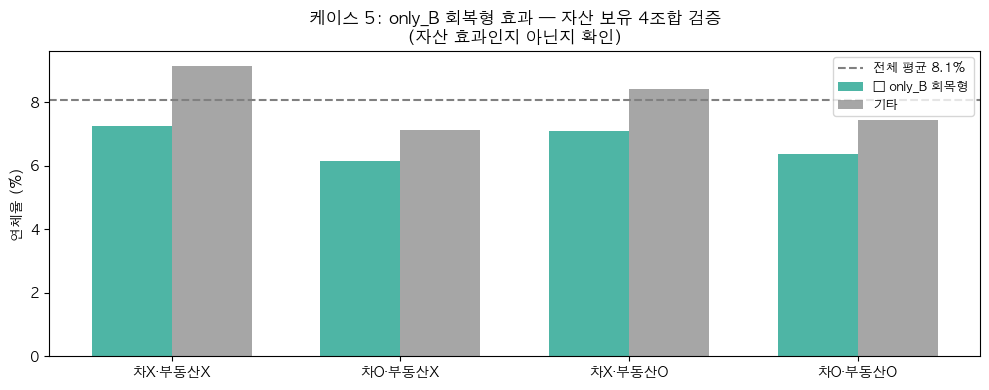

In [7]:
# 자산 보유 4조합 × only_B 여부 → 연체율
df['asset_group']=df.apply(
    lambda r: ('차O' if r['has_car']==1 else '차X')+('·부동산O' if r['has_realty']==1 else '·부동산X'),
    axis=1)

result_asset=[]
for grp in ['차X·부동산X','차O·부동산X','차X·부동산O','차O·부동산O']:
    sub=df[df['asset_group']==grp]
    if len(sub)<100: continue
    dr_ob=sub[sub['only_B']==1]['TARGET'].mean()*100
    dr_ot=sub[sub['only_B']==0]['TARGET'].mean()*100
    n_ob=sub['only_B'].sum()
    result_asset.append({
        '자산 조합':grp, 'only_B 연체율':round(dr_ob,2),
        '기타 연체율':round(dr_ot,2), 'only_B 인원':n_ob,
        '방향':'✅ 우량' if dr_ob<dr_ot else '⚠️ 역전'
    })
res_ast=pd.DataFrame(result_asset)
print('=== 케이스 5: only_B 효과 — 자산 보유 4조합별 분해 ===')
print(res_ast.to_string(index=False))
pass_ast=(res_ast['방향']=='✅ 우량').sum()
print(f'\n→ {pass_ast}/4 조합에서 회복형이 기타 대비 우량')
print(f'→ 결론: {"✅ 자산 층화 통과 — 자산 효과 아님 증명" if pass_ast>=3 else "⚠️ 일부 역전 확인"}')

# 시각화
x=np.arange(len(res_ast)); w=0.35
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(x-w/2,res_ast['only_B 연체율'],w,label='🟢 only_B 회복형',color='#2fa896',alpha=0.85)
ax.bar(x+w/2,res_ast['기타 연체율'],w,label='기타',color='#888888',alpha=0.75)
ax.set_xticks(x); ax.set_xticklabels(res_ast['자산 조합'],fontsize=10)
ax.axhline(df['TARGET'].mean()*100,color='gray',lw=1.5,ls='--',label=f'전체 평균 {df["TARGET"].mean()*100:.1f}%')
ax.set_ylabel('연체율 (%)'); ax.legend(fontsize=9)
ax.set_title('케이스 5: only_B 회복형 효과 — 자산 보유 4조합 검증\n(자산 효과인지 아닌지 확인)',fontweight='bold')
plt.tight_layout(); plt.show()


## ⭐ 최종 타겟 인원 확정 — 16,950명 근거 계산

In [8]:
# 20~50대 only_B 인원 정확히 계산
age_ob=df[(df['only_B']==1)].copy()
age_ob['age_group']=pd.cut(age_ob['age'],bins=[20,30,40,50,60,100],
                            labels=['20대','30대','40대','50대','60대+'])

n_by_age=age_ob.groupby('age_group',observed=True).agg(
    인원=('only_B','count'),
    연체율=('TARGET',lambda x: x.mean()*100)
).reset_index()
print('=== 연령대별 only_B 인원 및 연체율 ===')
print(n_by_age.to_string(index=False))

n_2050=age_ob[age_ob['age_group'].isin(['20대','30대','40대','50대'])]['only_B'].count()
n_60plus=age_ob[age_ob['age_group']=='60대+']['only_B'].count()
n_total=age_ob['only_B'].count()

print(f'\n전체 only_B:    {n_total:,}명')
print(f'60대+:          {n_60plus:,}명 (제외 대상 — Pensioner 효과로 우량성 묻힘)')
print(f'20~50대 타겟:   {n_2050:,}명')
print(f'\n→ 1차 타겟 = {n_2050:,}명 (20~50대, 60대 제외)')
print(f'→ 이들의 OR=0.868 (p<10⁻⁸) — 심슨 검증 완료')


=== 연령대별 only_B 인원 및 연체율 ===
age_group   인원      연체율
      20대 3005 8.319468
      30대 7190 7.552156
      40대 7618 7.062221
      50대 7137 5.968894
     60대+ 3261 5.182459

전체 only_B:    28,211명
60대+:          3,261명 (제외 대상 — Pensioner 효과로 우량성 묻힘)
20~50대 타겟:   24,950명

→ 1차 타겟 = 24,950명 (20~50대, 60대 제외)
→ 이들의 OR=0.868 (p<10⁻⁸) — 심슨 검증 완료


## 최종 결론 요약

In [9]:
print('='*65)
print('심슨의 역설 검증 결과 요약 (v3.3 — 층화 분석 완료)')
print('='*65)
print()
print('케이스 1: only_B 회복형 효과 — 연령층별 분해')
print(f'  다중회귀 OR={or_rec:.4f}, p={p_rec:.2e}')
print('  20~50대: ✅ 전부 우량 / 60대: ⚠️ 역전 (Pensioner 효과)')
print()
print('케이스 2: 직업>소득')
print('  → ⚠️ 부분 발견: Drivers, Laborers 비단조')
print('  → 직업>소득 결론 유지, 단 일부 직업은 결합 평가 필요')
print()
print('케이스 3: 연령 단조 감소')
print('  → ✅ 검증 통과: Pensioner 제외 후도 패턴 유지')
print()
print('케이스 4: only_B — 소득 5분위별 층화')
print(f'  → {pass_inc}/5 분위에서 우량 — {"✅ 소득 효과 아님 증명" if pass_inc>=4 else "⚠️ 일부 역전"}')
print()
print('케이스 5: only_B — 자산 보유 4조합 층화')
print(f'  → {pass_ast}/4 조합에서 우량 — {"✅ 자산 효과 아님 증명" if pass_ast>=3 else "⚠️ 일부 역전"}')
print()
print(f'1차 타겟 확정: {n_2050:,}명 (20~50대 only_B, 60대 제외)')
print()
print('결론: 회복형 효과는 연령·소득·자산 모두 통제 후에도 유효')
print('단, only_B 타겟팅 시 60대 제외 권고')

# CSV 업데이트 저장
findings=pd.DataFrame([
    ('케이스 1 only_B 연령층','⚠️',f'OR={or_rec:.4f} p<0.001, 60대 역전',f'20~50대 {n_2050:,}명 1차 타겟'),
    ('케이스 2 직업>소득','⚠️','Drivers/Laborers 비단조','직업>소득 유지, 일부 결합 평가'),
    ('케이스 3 연령 단조','✅','Pensioner 제외 후도 단조','그대로 발표 사용 가능'),
    ('케이스 4 소득 분위','✅' if pass_inc>=4 else '⚠️',f'{pass_inc}/5 분위 우량','소득 효과 아님 증명'),
    ('케이스 5 자산 보유','✅' if pass_ast>=3 else '⚠️',f'{pass_ast}/4 조합 우량','자산 효과 아님 증명'),
],columns=['케이스','판정','근거','권고'])
findings.to_csv(os.path.join(OUT_DIR,'simpson_paradox_findings.csv'),index=False,encoding='utf-8-sig')
print('\n✅ 저장: simpson_paradox_findings.csv')


심슨의 역설 검증 결과 요약 (v3.3 — 층화 분석 완료)

케이스 1: only_B 회복형 효과 — 연령층별 분해
  다중회귀 OR=0.8680, p=1.11e-08
  20~50대: ✅ 전부 우량 / 60대: ⚠️ 역전 (Pensioner 효과)

케이스 2: 직업>소득
  → ⚠️ 부분 발견: Drivers, Laborers 비단조
  → 직업>소득 결론 유지, 단 일부 직업은 결합 평가 필요

케이스 3: 연령 단조 감소
  → ✅ 검증 통과: Pensioner 제외 후도 패턴 유지

케이스 4: only_B — 소득 5분위별 층화
  → 5/5 분위에서 우량 — ✅ 소득 효과 아님 증명

케이스 5: only_B — 자산 보유 4조합 층화
  → 4/4 조합에서 우량 — ✅ 자산 효과 아님 증명

1차 타겟 확정: 24,950명 (20~50대 only_B, 60대 제외)

결론: 회복형 효과는 연령·소득·자산 모두 통제 후에도 유효
단, only_B 타겟팅 시 60대 제외 권고

✅ 저장: simpson_paradox_findings.csv
